In [ ]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

sns.set()

kirby_url="https://raw.githubusercontent.com/smart-stats/ds4bio_book/main/book/assetts/kirby21AllLevels.csv"
kirb21_df=pd.read_csv(kirby_url) #downlaod and read kirb21 into pandas 
kirby906a_ax_df=kirb21_df.loc[kirb21_df['rawid']=='kirby906a_ax.img'] #new data set generate by only subject with kirby906a_ax.img
kirby906a_ax_df.head(4) #a demonstration of successful new dataset generation, you will get the whole set using print()


,Unnamed: 0,rawid,roi,volume,min,max,mean,std,type,level,id,icv,tbv
12540,12541,kirby906a_ax.img,Telencephalon_L,467063,2.0,350.0,165.2599,57.1707,1,1,906,1195015,1123076
12541,12542,kirby906a_ax.img,Telencephalon_R,470488,2.0,337.0,171.8695,59.3001,1,1,906,1195015,1123076
12542,12543,kirby906a_ax.img,Diencephalon_L,8801,60.0,327.0,227.1878,31.2303,1,1,906,1195015,1123076
12543,12544,kirby906a_ax.img,Diencephalon_R,9054,63.0,415.0,231.6770,31.1780,1,1,906,1195015,1123076


In [11]:
#Probelm 1
type1_level1=kirby906a_ax_df.loc[(kirby906a_ax_df['type']==1) & (kirby906a_ax_df['level']==1)]
telencephalon_L_volume=sum(type1_level1.loc[type1_level1['roi']=='Telencephalon_L', 'volume'])
telencephalon_R_volume=sum(type1_level1.loc[type1_level1['roi']=='Telencephalon_R', 'volume'])
print("Telencephalon left volume: ", telencephalon_L_volume)
print("Telencephalon right volume: ", telencephalon_R_volume)

icv = sum(type1_level1["volume"])
tbv = sum(type1_level1[type1_level1['roi'] != "CSF"]['volume'])
telencephalon_total=telencephalon_L_volume+telencephalon_R_volume
print("Fraction of icv by telencephalon: ", telencephalon_total/icv)
print("Fraction of tbv by telencephalon: ", telencephalon_total/tbv)

Telencephalon left volume:  467063
Telencephalon right volume:  470488
Fraction of icv by telencephalon:  0.7845516583473847
Fraction of tbv by telencephalon:  0.8348063710737297


In [8]:
#problem 2
all_regions_df= (kirby906a_ax_df.groupby(['type','level'], as_index=False).agg(total_volume=('volume','sum'))) 
#a new function found online .agg total volume is a added new column volume is the input column and sum is th opreation
#can also done by this way 
# all_regions_df = (kirby906a_ax_df.groupby(["type", "level"], as_index=False)["volume"].sum().rename(columns={"volume": "total_volume"})
print(all_regions_df)

   type  level  total_volume
0     1      1       1195015
1     1      2       1195021
2     1      3       1195034
3     1      4       1195065
4     1      5       1195124
5     2      1       1195015
6     2      2       1195022
7     2      3       1195032
8     2      4       1195041
9     2      5       1195092


Text(0.5, 1.0, 'Type 1 Level 2 Regional Volumes')

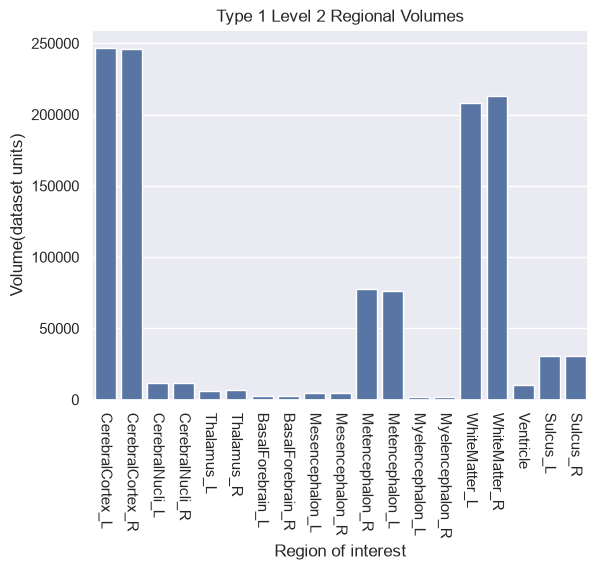

In [ ]:
#problem 3
type1_level2=kirby906a_ax_df.loc[(kirby906a_ax_df["type"]==1) & (kirby906a_ax_df["level"]==2)] #also you could add .sort("volume") so when yuo plot it could show from lopwest to larget volumes
sns.barplot(x="roi", y="volume", data=type1_level2)
plt.xticks(rotation=-90)
plt.xlabel("Region of interest")
plt.ylabel("Volume(dataset units)")
plt.title("Type 1 Level 2 Regional Volumes")